In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image
import time

keras.utils.set_random_seed(2)

base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

In [2]:
train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.


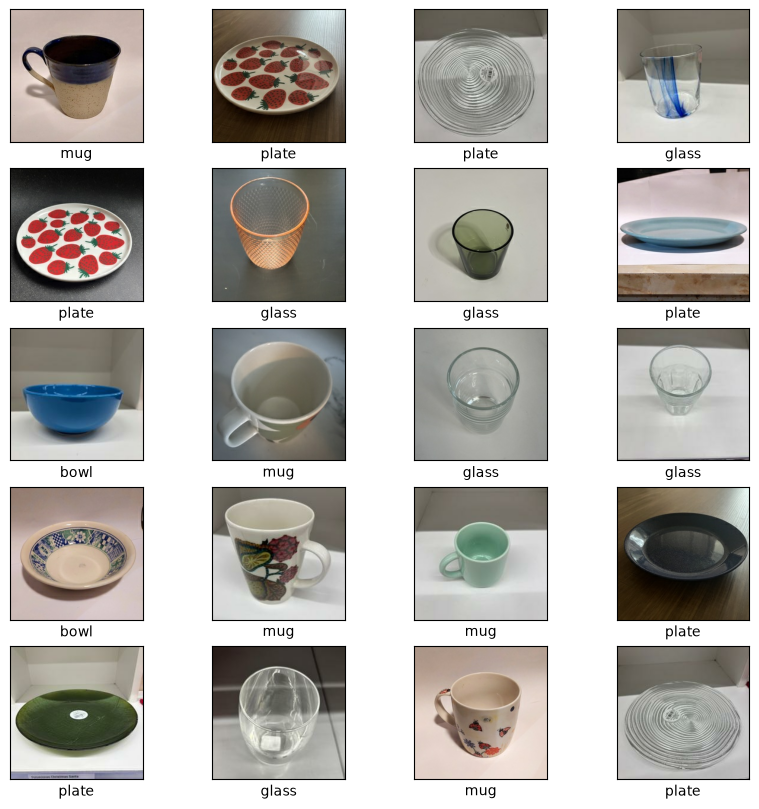

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

In [4]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)

conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2)
        
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
#x = layers.GlobalAveragePooling2D()(x) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,138,500 (80.64 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [7]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning_(feature_extraction).keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=8, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_dataset,
    epochs=70,
    validation_data=validation_dataset,
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

/opt/anaconda3/envs/keras/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.3682 - loss: 7.9844 - val_accuracy: 0.7312 - val_loss: 2.1414
Epoch 2/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.6588 - loss: 3.0708 - val_accuracy: 0.7849 - val_loss: 1.6206
Epoch 3/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.7872 - loss: 1.5129 - val_accuracy: 0.7849 - val_loss: 1.1804
Epoch 4/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8243 - loss: 1.4565 - val_accuracy: 0.9140 - val_loss: 0.5769
Epoch 5/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8784 - loss: 1.0111 - val_accuracy: 0.9247 - val_loss: 0.5977
Epoch 6/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.8919 - loss: 0.5067 - val_accuracy: 0.9140 - val_loss: 0.5608
Epoch 7/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8986 - loss: 0.5170 - val_accuracy: 0.9247 - val_loss: 0.5107
Epoch 8/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9054 - loss: 0.5955 - val_accuracy: 0.9032 - val_loss:

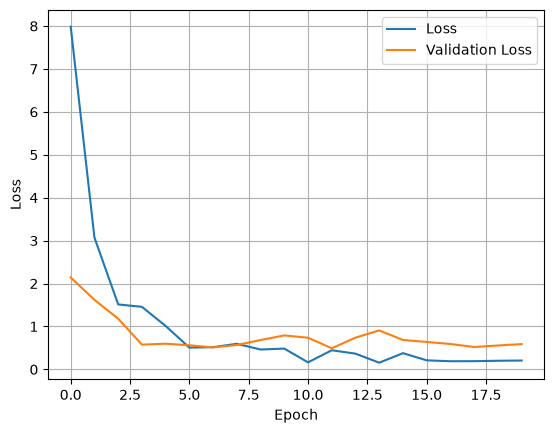

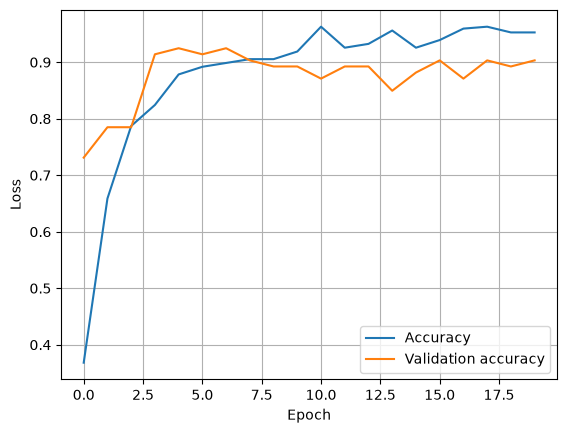

In [8]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

In [9]:
test_model = keras.models.load_model("fine_tuning_(feature_extraction).keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9053 - loss: 0.8122
Test accuracy: 0.905
Test loss: 0.812


## Fine Tuning Phase 

In [10]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
    
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])


In [11]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=8, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.9527 - loss: 0.3542 - val_accuracy: 0.9032 - val_loss: 0.7437
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9459 - loss: 0.2780 - val_accuracy: 0.8925 - val_loss: 0.7562
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9426 - loss: 0.3049 - val_accuracy: 0.8925 - val_loss: 0.7133
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9324 - loss: 0.3258 - val_accuracy: 0.8925 - val_loss: 0.5841
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9392 - loss: 0.2328 - val_accuracy: 0.9247 - val_loss: 0.4421
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9662 - loss: 0.1285 - val_accuracy: 0.9247 - val_loss: 0.4362
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9696 - loss: 0.0918 - val_accuracy: 0.8925 - val_loss: 0.4752
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9595 - loss: 0.1256 - val_accuracy: 0.8925 - val_loss:

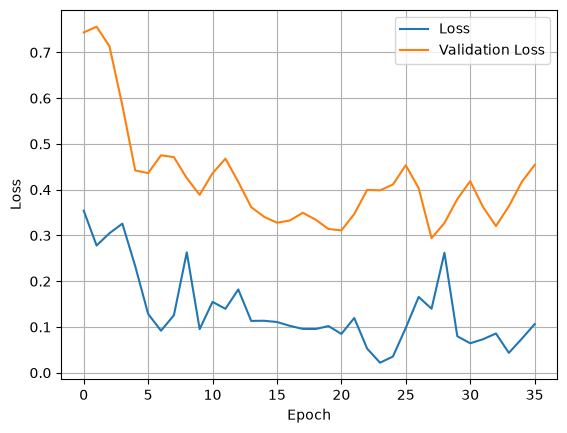

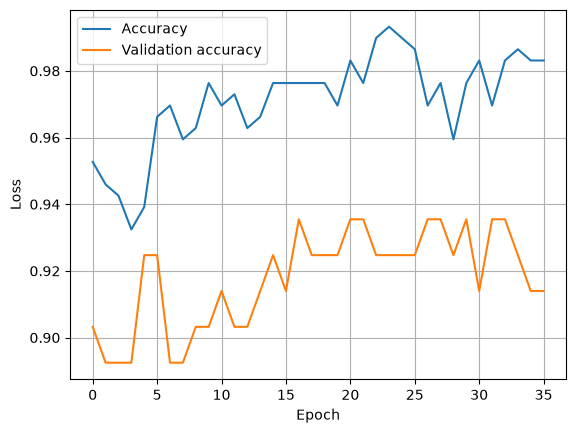

In [12]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

In [13]:
test_model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8947 - loss: 0.6741
Test accuracy: 0.895
Test loss: 0.674


In [14]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = test_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step
              precision    recall  f1-score   support

        bowl       0.92      0.88      0.90        26
       glass       0.85      0.92      0.88        24
         mug       0.85      0.81      0.83        21
       plate       0.96      0.96      0.96        24

    accuracy                           0.89        95
   macro avg       0.89      0.89      0.89        95
weighted avg       0.90      0.89      0.89        95



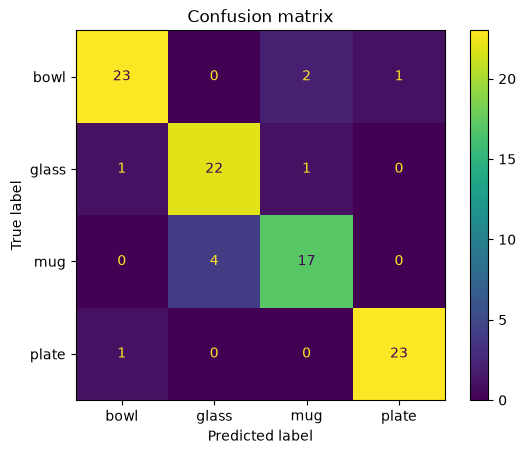

In [15]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


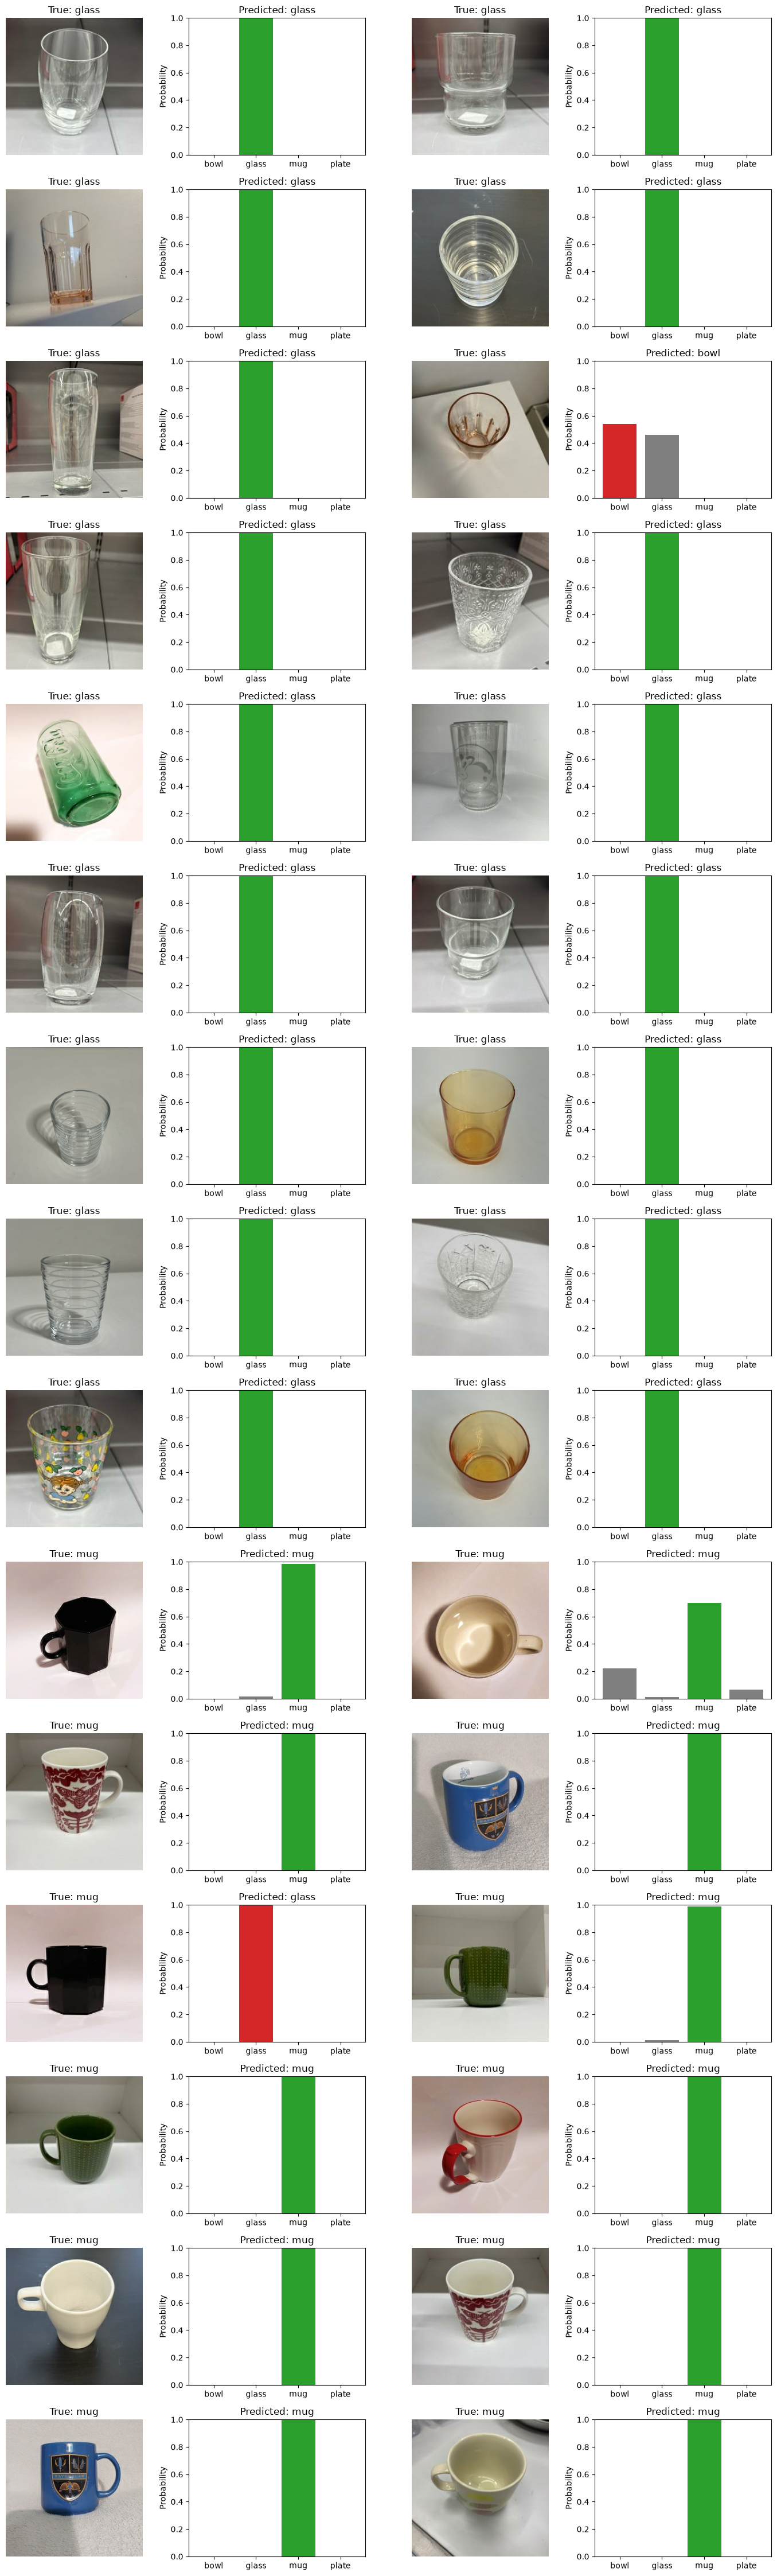

In [16]:
#x, y = next(iter(test_dataset)) 
batch_index = 1

for i, (x, y) in enumerate(test_dataset):
    if i == batch_index:
        break
        
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

Test|Phase|Modification|Test accuracy (%)|Test loss|Training time (s)|Conclusion|
|---|---|---|---|---|---|---|
|Original model | Phase 1 | - | 0.937 | 1.573 | 420.7 | In phase 1 (feature-extraction) test accuracy seems good but loss is not good|
|Original model | Phase 2 | - | 0.926 | 1.685 | 722.4 | In phase 2 (fine-tuning) test accuracy not better than phase 1 and also loss |
Version 1 | phase 1 | Add early stopping callback | 0.884 |  3.191 |  292.1 | Test accuracy and test loss worse because validation loss fluctuate a lot training stops early beacuse validation loss doesn't improve| 
Version 1 | phase 2 | Add early stopping callback | 0.895 | 2.508 | 360.0 | Test accuracy and test loss worse because validation loss fluctuate a lot and training stops early|
|Version 2|Phase 1 |Add learning rate 1e-4 |0.926|0.700|270.0| Accuracy is better and val loss decrease clearly from 3.19 to 0.70, it means the model is no longer making wrong predictions with extreme confidence|
|Version 2|Phase 2|-|0.968|0.585|531.8| Fine tuning accuracy is quite well and val loss decrease noticably from 2.508 to 0.585|
|Version 3| Phase 1| add GlobalAveragePooling2D layer instead flatten | 0.800 | 0.549 | 1032.8 | feature extraction accuracy is worse, validation is decrease little and training time is too slow takes notably much time|
|Version 3| Phase 2| - | 0.895 | 0.403 |479.4|Accuracy didn't improve and loss and accuracy curve fluctuale a lot |
|Version 4| Phase 1| modifies data augmentation RandomTranslation(0.1, 0.1), RandomContrast(0.2), RandomBrightness(0.2)|0.821|0.550|970.1 | There is no visible changes after adding stonger augmentation little improve in loss and accuracy|
|Version 4|phase 2|-|0.842|0.524|220.9| fine-tuning didn't help much as its accuracy and loss worsen|
|Version 5|phase 1| Change GlobalAveragePooling2D() layer to flatten() |0.905|0.812|424.8| loss worsen and accuracy improve a bit but still original model accuracy was better|
|Version 5|phase 2|-| 0.895|0.674|869,9|fine tuning didn't improve  but tarining time is also longer|


| Test | Phase | Modification | Test accuracy (%) | Test loss | Training time (s) | Conclusion |
|---|---|---|---:|---:|---:|---|
| Original model | Phase 1 | - | 0.937 | 1.573 | 420.7 | In phase 1 (feature extraction), test accuracy seems good but loss is not good. |
| Original model | Phase 2 | - | 0.926 | 1.685 | 722.4 | In phase 2 (fine-tuning), test accuracy is not better than phase 1, and loss is also worse. |
| Version 1 | Phase 1 | Add early stopping callback | 0.884 | 3.191 | 292.1 | Test accuracy and loss are worse because validation loss fluctuates a lot, causing training to stop early. |
| Version 1 | Phase 2 | Add early stopping callback | 0.895 | 2.508 | 360.0 | Test accuracy and loss are worse because validation loss fluctuates and training stops early. |
| Version 2 | Phase 1 | Add learning rate 1e-4 | 0.926 | 0.700 | 270.0 | Accuracy is good and validation loss decreases clearly from 3.19 to 0.70. |
| Version 2 | Phase 2 | - | 0.968 | 0.585 | 531.8 | Fine-tuning achieves good accuracy, and validation loss decreases noticeably from 2.508 to 0.585. |
| Version 3 | Phase 1 | Add GlobalAveragePooling2D instead of Flatten | 0.800 | 0.549 | 1032.8 | Feature-extraction accuracy is worse. Validation loss decreases slightly, and training takes considerably longer. |
| Version 3 | Phase 2 | - | 0.895 | 0.403 | 479.4 | Accuracy did not improve, and the loss and accuracy curves fluctuate considerably. |
| Version 4 | Phase 1 | Modify data augmentation: RandomTranslation(0.1, 0.1), RandomContrast(0.2), RandomBrightness(0.2) | 0.821 | 0.550 | 970.1 | Stronger augmentation produces no visible improvement, with only slight changes in loss and accuracy. |
| Version 4 | Phase 2 | - | 0.842 | 0.524 | 220.9 | Fine-tuning did not help much, as both accuracy and loss worsened. |
| Version 5 | Phase 1 | Change GlobalAveragePooling2D() to Flatten() | 0.905 | 0.812 | 424.8 | Loss worsened and accuracy improved slightly, but the original model performed better. |
| Version 5 | Phase 2 | - | 0.895 | 0.674 | 869.9 | Fine-tuning did not improve performance, and training time was longer. |


**Original model: Phase 1** 

```python

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2)
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()
```

**Original model: Phase 2** 

```python
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
```

**Version 1 Phase 1 & 2: Add EarlyStopping callbacks in compile**

**Version 2 Phase 1: Add learning rate 1e-4**

**Version 3 Phase 1 Add GlobalAveragePooling2D layer instead flatten**

```python
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2)
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.GlobalAveragePooling2D()(x) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()
```

**Version 4 Phase 1: Add RandomTranslation(0.1, 0.1), RandomContrast(0.2), RandomBrightness(0.2)**
```python

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2)
        
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
#x = layers.Flatten()(x)
x = layers.GlobalAveragePooling2D()(x) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()
```
**Version 5 Phase 1: Change GlobalAveragePooling2D() layer to flatten()**

```python
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2)
        
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()
```